<a href="https://colab.research.google.com/github/ShinAsakawa/ShinAsakawa.github.io/blob/master/2026notebooks/20260921hemi_neglect_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# hemi-neglect: 半側空間無視 計算モデル (2026年09月18日版)

`hemi-neglect_FRG/sim/` の Python 実装（`params.py`, `model.py`, `stimuli.py`, `scoring.py`,
`run.py`, `calibrate.py`）を **このノートブック単体で完結する形**で再構成したものです。
`sim/` フォルダを別途アップロードする必要はありません — 下のセルが `sim/*.py` を
Colab 上のランタイムに書き出し、そこから import します。

- 必須: numpy（Colab に標準搭載）
- 任意: matplotlib（図の表示）、scipy（較正の高精度化）。どちらも Colab に標準搭載。
- 実行順序: 上から順にすべてのセルを実行してください（Runtime → Run all）。
- 詳しい仕様は `6_simulation00.md`、使い方は `7_simulation_manual.md`、設計経緯は
  `sim/DESIGN_LOG.md` を参照（このリポジトリ内）。

座標系: `x∈[-1,1]`（x<0=左=対側）, `y∈[-0.62,0.62]`。損傷は右半球の gain
（`rho_bu_R, rho_td_R, rho_tpj_R, rho_gate_R, lc`）を1.0未満に下げて表現します。


## 0. 環境確認

In [1]:
import sys
print("Python:", sys.version)

import numpy as np
print("numpy:", np.__version__)

try:
    import matplotlib
    print("matplotlib:", matplotlib.__version__)
    HAS_MPL = True
except ImportError:
    print("matplotlib not available -> figures will be skipped")
    HAS_MPL = False

try:
    import scipy
    print("scipy:", scipy.__version__)
except ImportError:
    print("scipy not available -> calibration falls back to coordinate descent")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
    print("running in Google Colab")
except ImportError:
    IN_COLAB = False
    print("not running in Google Colab (local Jupyter?) -- download cell will be skipped")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
numpy: 2.1.3
matplotlib: 3.10.0
scipy: 1.16.3
running in Google Colab


<!-- ## 1. `sim/` のソースをこのランタイムに再構成する

以下の6セルは、`hemi-neglect_FRG/sim/` にある実際のファイルの内容を
**そのまま**書き出します（転記による差異が出ないよう、リポジトリのファイルから
直接生成しています）。 -->

In [2]:
import os
os.makedirs("sim", exist_ok=True)
print("created ./sim")


created ./sim


<!-- ### 1.1 `params.py` — パラメータ定義とプリセット -->

In [3]:
%%writefile sim/params.py
"""
params.py -- parameter sets for the reduced hemispatial-neglect simulation.

Coordinate convention (page/world units):
    x in [-1, +1]   -1 = far left (contralesional for a right-hemisphere lesion), +1 = far right
    y in [-0.62, +0.62]

Every "gain" parameter is 1.0 in a fully healthy hemisphere. A right-hemisphere
lesion is expressed by lowering the *_R gains (and optionally `lc`).

Mapping to the HCD / FRG (see ../3_UC.md, ../4_機能詳細.md):
    rho_bu     -- bottom-up salience gain of the hemispheric priority map      [U.V2-V4]/[U.V3A-MT] -> [U.IPS] ; R.priority-map-core
    rho_td     -- top-down weight gain (task set + value)                       [U.DLPFC]/[U.ACC] -> [U.IPS] ; R.task-set-and-goal, R.motivational-relevance-weighting
    rho_tpj    -- circuit-breaker / disengage gain                             [U.TPJ] -> [U.IPS] ; R.salient-event-detection
    rho_gate   -- basal-ganglia Go gain for orienting execution (direction)     [U.caudate]/[U.putamen] -> [U.GPi-SNr] -> [U.superior-colliculus] ; R.pallidal-disinhibition
    w_callosal -- interhemispheric competition strength                         [U.contra-FPN] <-> [U.IPS]/[U.FEF] ; R.interhemispheric-priority-balance
    lc         -- global noradrenergic arousal / vigilance level [0..1]         [U.LC] ; folded into every gain via (arousal_base + arousal_slope*lc)
"""
from __future__ import annotations
from dataclasses import dataclass, field, asdict
import json


@dataclass
class Params:
    # ---- grid ----
    nx: int = 201
    ny: int = 101
    x_half: float = 1.0
    y_half: float = 0.62

    # ---- hemispheric attentional gains (1.0 == healthy) ----
    rho_bu_L: float = 1.00
    rho_bu_R: float = 1.00
    rho_td_L: float = 1.00
    rho_td_R: float = 1.00
    rho_tpj_L: float = 1.00
    rho_tpj_R: float = 1.00
    rho_gate_L: float = 1.00
    rho_gate_R: float = 1.00

    # ---- shared ----
    w_callosal: float = 0.55          # opponent-process (contra-FPN) strength
    hemi_out_exp: float = 1.7         # exponent on the hemispheric output gain (steepens the neglect)
    lc: float = 1.00                  # arousal level [0..1]
    arousal_base: float = 0.55
    arousal_slope: float = 0.55       # gain_arousal = base + slope*lc  (healthy -> 1.10)

    # ---- salience field ----
    lambda_ecc: float = 1.4           # retinal eccentricity fall-off scale (cortical-magnification proxy)
    beta_hemi: float = 0.16           # width of the hemifield weighting sigmoid (retinal)
    ipsi_floor: float = 0.08          # residual ipsilateral representation of each hemisphere
    norm_sigma: float = 0.05          # divisive-normalisation semi-saturation
    norm_kmax: float = 0.35            # fraction of the field max added to the normalisation pool (caps peak P ~ 1.5)
    n_field_iter: int = 4             # Gauss-Seidel iterations for the coupled P_L / P_R

    # ---- feature-based attention (task set / DLPFC target template) ----
    fmatch_floor: float = 0.18        # residual priority for a non-matching item, healthy hemisphere
    fmatch_eps: float = 0.15          # regulariser in S_td / (S_bu + eps)

    # ---- inhibition of return ----
    w_ior: float = 2.2
    a_ior: float = 2.4
    sigma_ior: float = 0.070
    tau_ior: float = 9.0              # decay time-constant in "saccade" units

    # ---- FEF accumulator / saccade selection ----
    k_acc: float = 1.6               # accumulator drive gain
    leak_acc: float = 0.35
    theta_sacc: float = 1.0          # selection threshold
    dt_acc: float = 0.02
    max_inner: int = 400             # inner integration steps before forced move
    noise_acc: float = 0.012
    reset_frac: float = 0.85         # post-saccade accumulator reset scaled by rho_tpj_local

    # ---- marking (star cancellation) ----
    r_mark: float = 0.06             # a fixation within this radius of a target can mark it
    theta_mark: float = 0.30         # Go threshold to actually cancel
    max_saccades: int = 140
    patience: int = 3                # consecutive unproductive saccades -> "I'm done"
    min_saccades: int = 10
    give_up_frac: float = 0.46    # stop when represented remaining priority < frac * intact peak

    # ---- line bisection ----
    fix_bias_gain: float = 0.42       # habitual gaze shift per unit opponent asymmetry
    beta_hemi_line: float = 0.45      # hemifield-weighting width for the line task
    k_periph: float = 1.0             # steepness of the leftward compression gradient (x right-hemisphere damage)
    delta_motor: float = 0.14         # rightward motor bias coefficient (premotor component), *half-line
    c_crossover: float = 0.0          # length-dependent term (0 = off); >0 gives leftward error on short lines
    L_ref: float = 0.80              # reference line length for the crossover term

    # ---- misc ----
    seed: int = 0

    # -------------------------------------------------------------
    def gain_arousal(self) -> float:
        return self.arousal_base + self.arousal_slope * self.lc

    def to_json(self, path: str) -> None:
        with open(path, "w", encoding="utf-8") as f:
            json.dump(asdict(self), f, indent=2)

    @classmethod
    def from_json(cls, path: str) -> "Params":
        with open(path, encoding="utf-8") as f:
            d = json.load(f)
        return cls(**d)

    def copy_with(self, **kw) -> "Params":
        d = asdict(self)
        d.update(kw)
        return Params(**d)


# --------------------------------------------------------------------------
# Presets
# --------------------------------------------------------------------------
def healthy() -> Params:
    """Healthy adult, with a small leftward asymmetry -> pseudoneglect."""
    return Params(
        rho_bu_R=1.03, rho_td_R=1.02,      # right hemisphere slightly stronger
        rho_bu_L=1.00, rho_td_L=1.00,
    )


def lesion(level: str) -> Params:
    """Right-hemisphere lesion of graded severity (perceptual + premotor mix)."""
    lv = {
        "mild":     dict(rho_bu_R=0.82, rho_td_R=0.82, rho_tpj_R=0.68, rho_gate_R=0.88, lc=0.95),
        "moderate": dict(rho_bu_R=0.60, rho_td_R=0.58, rho_tpj_R=0.46, rho_gate_R=0.68, lc=0.87),
        "severe":   dict(rho_bu_R=0.36, rho_td_R=0.32, rho_tpj_R=0.26, rho_gate_R=0.44, lc=0.74),
    }[level]
    return healthy().copy_with(**lv)


def lesion_perceptual() -> Params:
    """'Input' / perceptual-attentional neglect: left priority collapses, gate spared."""
    return healthy().copy_with(rho_bu_R=0.40, rho_td_R=0.42, rho_tpj_R=0.55, rho_gate_R=0.92, lc=0.9)


def lesion_premotor() -> Params:
    """'Output' / directional-hypokinesia neglect: perception near-normal, leftward orienting fails."""
    return healthy().copy_with(rho_bu_R=0.90, rho_td_R=0.90, rho_tpj_R=0.80, rho_gate_R=0.33, lc=0.95)


def lesion_disengage() -> Params:
    """Predominant disengagement deficit (TPJ-weighted)."""
    return healthy().copy_with(rho_bu_R=0.80, rho_td_R=0.80, rho_tpj_R=0.22, rho_gate_R=0.85, lc=0.9)


PRESETS = {
    "healthy": healthy,
    "mild": lambda: lesion("mild"),
    "moderate": lambda: lesion("moderate"),
    "severe": lambda: lesion("severe"),
    "perceptual": lesion_perceptual,
    "premotor": lesion_premotor,
    "disengage": lesion_disengage,
}


Writing sim/params.py


### 1.2 `model.py` — 提案モデル本体（NeglectModel）

In [4]:
%%writefile sim/model.py
"""
model.py -- reduced 2-D dynamical model of the fronto-parieto-basal-ganglia
spatial-attention loop, used to simulate BIT line bisection and star cancellation.

The model is a compressed, runnable version of the HCD/FRG built in ../.. :

  bottom-up salience   S_bu(x,y)           <- [U.V1],[U.V2-V4],[U.V3A-MT]
  top-down weight       S_td(x,y)           <- [U.DLPFC],[U.ACC]
  hemispheric priority  P_L, P_R            <- [U.IPS] (R.priority-map-core), one field per hemisphere,
                                               each covering mostly the contralateral hemifield
  opponent process      P_h <- ... - w_call*mirror(P_other)   <- [U.contra-FPN] (R.interhemispheric-priority-balance)
  divisive norm + LC    P_h = g_arousal * relu(R_h)/(sigma^2 + <R_h>)   <- [U.LC]
  accumulator           a(x,y)              <- [U.FEF] (R.cortical-target-selection); ramps on P, wins at threshold
  BG Go gate            gate_field(x,y)     <- [U.caudate]/[U.putamen]/[U.GPi-SNr] (R.pallidal-disinhibition);
                                               direction-specific, scales the drive and the marking action
  circuit breaker       post-saccade reset  <- [U.TPJ] (R.salient-event-detection); weak reset -> "magnetic" gaze
  inhibition of return  IOR(x,y)            -- exploration term (approximates the adaptation current in [U.IPS]/[U.TPJ])

Sign convention: x<0 = left = contralesional for a right-hemisphere lesion.
"""
from __future__ import annotations
import numpy as np

from params import Params


# --------------------------------------------------------------------------
def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


class NeglectModel:
    def __init__(self, p: Params):
        self.p = p
        self.rng = np.random.default_rng(p.seed)
        xs = np.linspace(-p.x_half, p.x_half, p.nx)
        ys = np.linspace(-p.y_half, p.y_half, p.ny)
        self.xs, self.ys = xs, ys
        self.X, self.Y = np.meshgrid(xs, ys)        # shape (ny, nx)
        self.dx = xs[1] - xs[0]
        self.dy = ys[1] - ys[0]

    # ---- geometry helpers -------------------------------------------------
    def _mirror_x(self, fld):
        """Reflect a field about x = 0 (homotopic / callosal target)."""
        return fld[:, ::-1]

    def _hemifield_weights(self, fx):
        """Retinotopic weighting: right hemisphere over-represents the left retinal field."""
        p = self.p
        rx = self.X - fx
        wR = p.ipsi_floor + (1.0 - p.ipsi_floor) * _sigmoid(-rx / p.beta_hemi)
        wL = p.ipsi_floor + (1.0 - p.ipsi_floor) * _sigmoid(rx / p.beta_hemi)
        return wL, wR

    # ---- salience -------------------------------------------------------
    def salience(self, items, fx, fy):
        """
        items: list of dicts {x, y, sigma, amp, match}  (page coords, match in [0,1])
        returns S_bu, S_td  (both shape (ny, nx)), with retinal-eccentricity fall-off.
        """
        p = self.p
        S_bu = np.zeros_like(self.X)
        S_td = np.zeros_like(self.X)
        for it in items:
            ex = it["x"] - fx
            ey = it["y"] - fy
            r = np.hypot(ex, ey)
            ecc = 1.0 / (1.0 + (r / p.lambda_ecc) ** 2)
            g = np.exp(-(((self.X - it["x"]) ** 2 + (self.Y - it["y"]) ** 2) /
                         (2.0 * it["sigma"] ** 2)))
            a = it["amp"] * ecc * g
            S_bu += a
            S_td += it.get("match", 1.0) * a
        return S_bu, S_td

    def bar_salience(self, x_left, x_right, y0, amp, thickness, fx, fy):
        """Analytic salience for a horizontal line-bisection bar."""
        p = self.p
        edge = 0.02
        sx = (_sigmoid((self.X - x_left) / edge) * _sigmoid((x_right - self.X) / edge))
        sy = np.exp(-((self.Y - y0) ** 2) / (2.0 * thickness ** 2))
        base = amp * sx * sy
        r = np.hypot(self.X - fx, self.Y - fy)
        ecc = 1.0 / (1.0 + (r / p.lambda_ecc) ** 2)
        s = base * ecc
        return s, s.copy()

    # ---- priority field -------------------------------------------------
    def priority(self, S_bu, S_td, IOR, fx, P_prev=None):
        """Coupled hemispheric priority maps -> combined priority P.

        Feature-based attention (DLPFC task set): a multiplicative match modulation
        fmod_h = floor_h + (1-floor_h) * (S_td / (S_bu + eps)), where a hemisphere
        with weak top-down (low rho_td_h) has a higher floor -> poorer distractor
        rejection in its hemifield.
        """
        p = self.p
        wL, wR = self._hemifield_weights(fx)
        g = p.gain_arousal()
        Mnorm = np.clip(S_td / (S_bu + p.fmatch_eps), 0.0, 1.0)
        floor_L = 1.0 - min(p.rho_td_L, 1.0) * (1.0 - p.fmatch_floor)
        floor_R = 1.0 - min(p.rho_td_R, 1.0) * (1.0 - p.fmatch_floor)
        fmod_L = floor_L + (1.0 - floor_L) * Mnorm
        fmod_R = floor_R + (1.0 - floor_R) * Mnorm

        if P_prev is None:
            P_L = np.zeros_like(self.X)
            P_R = np.zeros_like(self.X)
        else:
            P_L, P_R = P_prev

        for _ in range(p.n_field_iter):
            R_L = ((p.rho_bu_L * wL * S_bu + p.rho_td_L * wL * S_td) * fmod_L
                   - p.w_ior * IOR - p.w_callosal * self._mirror_x(P_R))
            R_R = ((p.rho_bu_R * wR * S_bu + p.rho_td_R * wR * S_td) * fmod_R
                   - p.w_ior * IOR - p.w_callosal * self._mirror_x(P_L))
            R_L = np.maximum(R_L, 0.0)
            R_R = np.maximum(R_R, 0.0)
            # SHARED (global) divisive normalisation pool -> a weakened hemisphere
            # loses the inter-hemispheric competition (this is what produces neglect).
            Rsum = R_L + R_R
            denom = p.norm_sigma ** 2 + Rsum.mean() + p.norm_kmax * Rsum.max()
            P_L = g * R_L / denom
            P_R = g * R_R / denom

        # hemispheric output gain that survives normalisation: a damaged hemisphere
        # produces an absolutely lower priority for its hemifield (not just relatively).
        hemi_out_L = (0.5 * (p.rho_bu_L + p.rho_td_L)) ** p.hemi_out_exp
        hemi_out_R = (0.5 * (p.rho_bu_R + p.rho_td_R)) ** p.hemi_out_exp
        P_L = P_L * hemi_out_L
        P_R = P_R * hemi_out_R
        P = P_L + P_R
        return P, (P_L, P_R)

    def gate_field(self, fx):
        """
        Direction-specific basal-ganglia Go gain (R.pallidal-disinhibition):
        orienting into the contralesional hemispace is gated by rho_gate_R.
        Uses mainly egocentric position (page x vs body midline ~ 0), with a small
        retinal component, so a far-left target stays hard to reach regardless of
        where the eyes have drifted (directional hypokinesia).
        """
        p = self.p
        b = 0.10
        ego = _sigmoid(-self.X / b)                       # 1 on the left of the page
        ret = _sigmoid(-(self.X - fx) / b)                # 1 on the left of current gaze
        left_frac = 0.75 * ego + 0.25 * ret
        return p.rho_gate_L * (1.0 - left_frac) + p.rho_gate_R * left_frac

    # ---- one search episode (star cancellation) ------------------------
    def run_search(self, items, targets, f0=(0.0, 0.0)):
        """
        Free visual search with cancellation.
        items:   all page objects (targets + distractors) as salience dicts
        targets: subset of `items` that are the to-be-cancelled small stars

        Neglect emerges from three things acting together:
          (1) low left-hemifield priority (weak right hemisphere -> R.priority-map-core),
          (2) a right-biased termination signal: the patient stops when the priority
              they still *represent* falls below a fraction of its initial peak, and
          (3) directional gating (rho_gate_R) that can block leftward saccades even
              when priority is adequate (directional hypokinesia).
        """
        p = self.p
        fx, fy = f0
        IOR = np.zeros_like(self.X)           # transient exploration suppression
        done = np.ones_like(self.X)           # permanent suppression at cancelled items
        a = np.zeros_like(self.X)
        P_prev = None
        marked = []
        target_xy = np.array([[t["x"], t["y"]] for t in targets]) if targets else np.zeros((0, 2))
        fixations = []
        t_now = 0.0
        p0_max = None
        last_find_step = -1

        for step in range(p.max_saccades):
            S_bu, S_td = self.salience(items, fx, fy)
            P, P_prev = self.priority(S_bu, S_td, IOR, fx, P_prev)
            P = P * done
            if p0_max is None:
                # stable reference: the intact (ipsilesional / right-page) priority peak
                p0_max = float(np.maximum(P[:, self.xs >= 0.0].max(), 1e-3))
            gate = self.gate_field(fx)
            drive = np.maximum(P, 0.0) * gate

            a *= 0.04
            inner = 0
            while inner < p.max_inner:
                a += p.dt_acc * (p.k_acc * drive * p.gain_arousal() - p.leak_acc * a)
                a += p.noise_acc * np.sqrt(p.dt_acc) * self.rng.standard_normal(a.shape)
                np.maximum(a, 0.0, out=a)
                inner += 1
                if a.max() >= p.theta_sacc:
                    break

            iy, ix = np.unravel_index(np.argmax(a), a.shape)
            x_star, y_star = self.xs[ix], self.ys[iy]

            moving_left = (x_star - fx) < -1e-6
            rho_gate_dir = p.rho_gate_R if moving_left else p.rho_gate_L
            rho_tpj_dir = p.rho_tpj_R if moving_left else p.rho_tpj_L

            dwell = 0.16 + 0.34 / max(1e-3, rho_tpj_dir * p.gain_arousal())
            t_now += 0.04 + inner * p.dt_acc + dwell

            # transient IOR at the departed and the arrived location
            IOR *= np.exp(-1.0 / p.tau_ior)
            for (cx, cy) in ((fx, fy), (x_star, y_star)):
                IOR += p.a_ior * np.exp(-(((self.X - cx) ** 2 + (self.Y - cy) ** 2) /
                                          (2.0 * p.sigma_ior ** 2)))

            fx, fy = x_star, y_star

            marked_id = -1
            if len(target_xy):
                d = np.hypot(target_xy[:, 0] - fx, target_xy[:, 1] - fy)
                j = int(np.argmin(d))
                if d[j] <= p.r_mark:
                    go = rho_gate_dir * (a.max() / p.theta_sacc) * targets[j].get("match", 1.0)
                    if j in marked:
                        marked_id = -2                                   # perseverative re-fixation
                    elif go >= p.theta_mark:
                        marked.append(j)
                        marked_id = j
                        last_find_step = step
                        done *= 1.0 - np.exp(-(((self.X - fx) ** 2 + (self.Y - fy) ** 2) /
                                              (2.0 * (1.4 * p.sigma_ior) ** 2)))  # permanent

            fixations.append((float(fx), float(fy), float(t_now), int(marked_id)))

            if len(marked) == len(targets):
                break
            if step + 1 >= p.min_saccades:
                # 'represented' remaining priority (uses the damaged map -> right-biased)
                rem_max = float((np.maximum(P, 0.0) * done).max())
                stale = step - last_find_step
                if rem_max < p.give_up_frac * p0_max and stale >= p.patience:
                    break
                if stale >= p.patience + 8:
                    break

        return {
            "fixations": fixations,
            "marked": [int(m) for m in marked],
            "P_final": P,
            "IOR_final": IOR,
        }

    # ---- one line-bisection judgement --------------------------------
    def _effective_hemistrength(self):
        """
        Opponent-process (contra-FPN) effective strength of each hemisphere.
        Divisive mutual inhibition: a weak hemisphere is further weakened by the
        (relatively unopposed) intact hemisphere.
        """
        p = self.p
        sRH = p.rho_bu_R + p.rho_td_R        # right hemisphere -> LEFT hemispace
        sLH = p.rho_bu_L + p.rho_td_L        # left  hemisphere -> RIGHT hemispace
        sRH_eff = sRH ** 2 / (sRH + p.w_callosal * sLH)
        sLH_eff = sLH ** 2 / (sLH + p.w_callosal * sRH)
        return sRH_eff, sLH_eff

    def _representation_profile(self, xr, fx_hab):
        """
        rep(x): perceived salience density of the line at page position x.
        Left-field pieces are carried by the (possibly damaged) right hemisphere,
        right-field pieces by the left hemisphere; plus a leftward 'compression'
        gradient whose steepness grows with right-hemisphere damage.
        """
        p = self.p
        sRH_eff, sLH_eff = self._effective_hemistrength()
        rx = xr - fx_hab
        b = p.beta_hemi_line
        base = sLH_eff * _sigmoid(rx / b) + sRH_eff * _sigmoid(-rx / b)
        ratio = sRH_eff / max(sLH_eff, 1e-6)               # 1 = symmetric, <1 = left underrepresented
        comp = np.where(rx >= 0.0, 1.0,
                        np.exp(-p.k_periph * (1.0 - ratio) * (-rx)))
        return base * comp, (sRH_eff, sLH_eff, ratio)

    def habitual_fixation_x(self):
        """Spontaneous horizontal gaze: ~0 (slightly left) in health, rightward in neglect."""
        sRH_eff, sLH_eff = self._effective_hemistrength()
        bias = (sLH_eff - sRH_eff) / (sLH_eff + sRH_eff)   # >0 in right-hemisphere neglect
        return float(self.p.fix_bias_gain * bias)

    def run_bisection_line(self, x_left, x_right, y0, fx_hab):
        """
        Balance-point model of bisection (opponent-process / Bisiach / TVA-style).
        The mark goes where the perceived extent of the two half-lines is equal,
        i.e. the median of the perceived-salience profile over the line.
        """
        p = self.p
        xc = 0.5 * (x_left + x_right)
        half = 0.5 * (x_right - x_left)
        L = x_right - x_left

        xr = np.linspace(x_left, x_right, 401)
        rep, (sRH_eff, sLH_eff, ratio) = self._representation_profile(xr, fx_hab)
        rep = np.maximum(rep, 1e-9)
        c = np.cumsum(rep)
        c /= c[-1]
        b_perc = float(np.interp(0.5, c, xr))

        motor = p.delta_motor * (1.0 - p.rho_gate_R) * half          # premotor rightward bias
        crossover = p.c_crossover * (p.L_ref - L)                    # +ve -> leftward error, short lines
        b_mark = b_perc + motor - crossover

        dev = b_mark - xc
        pct = 100.0 * dev / half                                     # +ve = rightward (ipsilesional)
        return {
            "x_left": x_left, "x_right": x_right, "y": y0,
            "true_center": xc, "b_perc": float(b_perc), "b_mark": float(b_mark),
            "dev": float(dev), "pct_dev": float(pct),
            "sRH_eff": float(sRH_eff), "sLH_eff": float(sLH_eff),
        }

    def run_bisection(self, lines, display_items=None, f0=(0.0, 0.0)):
        """lines: list of dicts {x_left, x_right, y}. display_items is accepted but unused."""
        fx_hab = self.habitual_fixation_x()
        results = [self.run_bisection_line(ln["x_left"], ln["x_right"], ln["y"], fx_hab)
                   for ln in lines]
        return {"fixation": (fx_hab, 0.0), "lines": results}


Writing sim/model.py


### 1.3 `stimuli.py` — BIT相当の刺激生成

In [5]:
%%writefile sim/stimuli.py
"""
stimuli.py -- stimulus generators for BIT line bisection and star cancellation.

Layouts are *statistically equivalent* to the BIT sheets (item counts, density,
left/right symmetry) but are NOT the copyrighted BIT layouts. Positions are in
page coordinates x in [-1,1], y in [-0.62,0.62].
"""
from __future__ import annotations
import json
import numpy as np


# --------------------------------------------------------------------------
# Line bisection: 3 lines of equal length, staggered horizontally (BIT-style).
# --------------------------------------------------------------------------
def bit_line_bisection(length: float = 0.80):
    """Return {'lines': [...], 'display_items': [...]}"""
    half = length / 2.0
    # BIT: upper line shifted left, middle centred-ish, lower shifted left again.
    centres = [(-0.22, 0.34), (0.06, 0.00), (-0.14, -0.34)]
    lines = []
    display_items = []
    for cx, cy in centres:
        xl, xr = cx - half, cx + half
        xl = max(xl, -0.98)
        xr = min(xr, 0.98)
        lines.append(dict(x_left=float(xl), x_right=float(xr), y=float(cy)))
        # represent each line by a few salience blobs for the free-viewing phase
        for t in np.linspace(0.15, 0.85, 4):
            display_items.append(dict(x=float(xl + t * (xr - xl)), y=float(cy),
                                      sigma=0.10, amp=1.0, match=1.0))
    return dict(lines=lines, display_items=display_items)


# --------------------------------------------------------------------------
# Star cancellation: ~54 small stars (targets) among large stars, letters, words.
# --------------------------------------------------------------------------
def bit_star_cancellation(seed: int = 1):
    rng = np.random.default_rng(seed)
    xlim, ylim = 0.90, 0.54
    n_small = 54          # targets
    n_large = 52
    n_letter = 13
    n_word = 10

    def scatter(n, jitter=0.035, cols=None, rows=None):
        cols = cols or max(4, int(round(np.sqrt(n * (xlim / ylim)))))
        rows = rows or int(np.ceil(n / cols))
        pts = []
        k = 0
        for r in range(rows):
            for c in range(cols):
                if k >= n:
                    break
                gx = -xlim + 2 * xlim * (c + 0.5) / cols
                gy = -ylim + 2 * ylim * (r + 0.5) / rows
                gx += rng.uniform(-jitter, jitter) * 2
                gy += rng.uniform(-jitter, jitter) * 2
                pts.append((float(np.clip(gx, -0.97, 0.97)),
                            float(np.clip(gy, -0.60, 0.60))))
                k += 1
        return pts

    items = []
    targets = []
    # interleave targets and large stars on a shared jittered grid so that
    # left/right density is symmetric
    small_pts = scatter(n_small, cols=11)
    large_pts = scatter(n_large, cols=11, jitter=0.045)
    for (x, y) in small_pts:
        d = dict(x=x, y=y, sigma=0.028, amp=0.85, match=1.0, kind="small_star", target=True)
        items.append(d)
        targets.append(d)
    for (x, y) in large_pts:
        # large stars are physically more salient but are NOT the target -> low match
        items.append(dict(x=x + 0.01, y=y + 0.02, sigma=0.05, amp=1.25,
                          match=0.35, kind="large_star", target=False))
    for (x, y) in scatter(n_letter, cols=7, jitter=0.05):
        items.append(dict(x=x, y=y, sigma=0.035, amp=0.9, match=0.25,
                          kind="letter", target=False))
    for (x, y) in scatter(n_word, cols=5, jitter=0.06):
        items.append(dict(x=x, y=y, sigma=0.07, amp=1.0, match=0.15,
                          kind="word", target=False))

    return dict(items=items, targets=targets,
                target_index=[i for i, it in enumerate(items) if it.get("target")])


# --------------------------------------------------------------------------
def save_stim(stim: dict, path: str):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(stim, f, indent=2)


def load_stim(path: str) -> dict:
    with open(path, encoding="utf-8") as f:
        return json.load(f)


Writing sim/stimuli.py


### 1.4 `scoring.py` — スコアリング（BIT風指標）

In [9]:
%%writefile sim/scoring.py
"""
scoring.py -- map model output onto BIT-style scores and continuous indices.

Continuous measures are the primary output; the BIT band scores are
*approximations* of the BIT manual (the exact cut-offs are proprietary).
"""
from __future__ import annotations
import numpy as np


# --------------------------------------------------------------------------
# Line bisection
# --------------------------------------------------------------------------
def _bisect_points(pct_dev: float) -> int:
    a = abs(pct_dev)
    if a <= 8:
        return 3
    if a <= 16:
        return 2
    if a <= 30:
        return 1
    return 0


def score_bisection(res: dict) -> dict:
    lines = res["lines"]
    per = []
    for ln in lines:
        per.append(dict(y=ln["y"], true_center=ln["true_center"],
                        b_mark=ln["b_mark"], pct_dev=ln["pct_dev"],
                        bit_points=_bisect_points(ln["pct_dev"])))
    pcts = np.array([p["pct_dev"] for p in per])
    return dict(
        fixation=res["fixation"],
        lines=per,
        mean_pct_dev=float(pcts.mean()),
        max_pct_dev=float(pcts[np.argmax(np.abs(pcts))]),
        bit_line_bisection_score=int(sum(p["bit_points"] for p in per)),   # 0..9
        neglect_sign="right" if pcts.mean() > 2 else ("left" if pcts.mean() < -2 else "none"),
    )


# --------------------------------------------------------------------------
# Star cancellation
# --------------------------------------------------------------------------
def score_star(res: dict, targets: list, page_midline: float = 0.0) -> dict:
    marked = res["marked"]
    n_tot = len(targets)
    tx = np.array([t["x"] for t in targets])

    cancelled = np.array(sorted(marked), dtype=int)
    n_cancelled = len(cancelled)
    left_ids = np.where(tx < page_midline)[0]
    right_ids = np.where(tx >= page_midline)[0]
    n_left_tot, n_right_tot = len(left_ids), len(right_ids)
    n_left_c = int(np.isin(cancelled, left_ids).sum())
    n_right_c = int(np.isin(cancelled, right_ids).sum())

    # centre of cancellation (approx. Rorden & Karnath 2010):
    # normalise target x to [-1, 1] over the target array, average over cancellations
    xmin, xmax = tx.min(), tx.max()
    xnorm = 2 * (tx - xmin) / (xmax - xmin) - 1.0
    coc = float(xnorm[cancelled].mean()) if n_cancelled else float("nan")

    # search-path measures
    fx = np.array([f[0] for f in res["fixations"]])
    fy = np.array([f[1] for f in res["fixations"]])
    ft = np.array([f[2] for f in res["fixations"]])
    mid = np.array([f[3] for f in res["fixations"]])
    path_len = float(np.hypot(np.diff(fx), np.diff(fy)).sum()) if len(fx) > 1 else 0.0
    revisits = int((mid == -2).sum())
    start_quadrant = ("right" if len(fx) and fx[0] > 0.05 else
                      "left" if len(fx) and fx[0] < -0.05 else "centre")
    total_time = float(ft[-1]) if len(ft) else 0.0

    return dict(
        n_targets=n_tot,
        n_cancelled=n_cancelled,
        n_left_cancelled=n_left_c, n_left_total=n_left_tot,
        n_right_cancelled=n_right_c, n_right_total=n_right_tot,
        left_omissions=n_left_tot - n_left_c,
        right_omissions=n_right_tot - n_right_c,
        centre_of_cancellation=coc,             # >0 -> cancellations shifted right (neglect)
        revisits=revisits,
        path_length=path_len,
        start_quadrant=start_quadrant,
        n_saccades=len(fx),
        total_time=total_time,
        bit_star_score=int(n_cancelled),        # 0..54
        neglect_flag=bool((n_left_tot - n_left_c) - (n_right_tot - n_right_c) >= 2 or coc > 0.08),
    )


Writing sim/scoring.py


### 1.5 `run.py` — 実行ドライバ（run_bisection, run_star, 図の生成）

In [10]:
%%writefile sim/run.py
#!/usr/bin/env python
"""
run.py -- command-line driver for the reduced hemispatial-neglect simulation.

Examples
--------
  # built-in demo: healthy + lesion presets on both tasks, prints a table
  python run.py --demo

  # single run, a preset
  python run.py --task star      --preset moderate --out out/ --fig
  python run.py --task bisection --preset severe   --out out/

  # single run, an explicit parameter file
  python run.py --task star --params my_params.json --stim my_stim.json --out out/
"""
from __future__ import annotations
import argparse
import csv
import json
import os
import sys

import numpy as np

from params import Params, PRESETS
from model import NeglectModel
from stimuli import bit_line_bisection, bit_star_cancellation, load_stim, save_stim
import scoring


def _write_json(obj, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)


def _mean_over_seeds(fn, n):
    outs = [fn(s) for s in range(n)]
    return outs


# --------------------------------------------------------------------------
def run_star(p: Params, stim=None, out=None, fig=False, n_seeds=1):
    if stim is None:
        stim = bit_star_cancellation(seed=1)
    items, targets = stim["items"], stim["targets"]

    runs = []
    for s in range(n_seeds):
        m = NeglectModel(p.copy_with(seed=p.seed + s))
        res = m.run_search(items, targets)
        runs.append(scoring.score_star(res, targets))
        last_res, last_model = res, m

    agg = _aggregate(runs)
    if out:
        os.makedirs(out, exist_ok=True)
        _write_json(dict(params_preset=getattr(p, "_preset", None), scores=agg, runs=runs),
                    os.path.join(out, "star_scores.json"))
        with open(os.path.join(out, "star_trace.csv"), "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["step", "x", "y", "t", "marked_id"])
            for i, (x, y, t, mid) in enumerate(last_res["fixations"]):
                w.writerow([i, f"{x:.4f}", f"{y:.4f}", f"{t:.3f}", mid])
        if fig:
            _fig_star(last_model, stim, last_res, os.path.join(out, "star.png"))
    return agg


def run_bisection(p: Params, stim=None, out=None, fig=False, n_seeds=1):
    if stim is None:
        stim = bit_line_bisection()
    lines = stim["lines"]
    di = stim.get("display_items")

    runs = []
    for s in range(n_seeds):
        m = NeglectModel(p.copy_with(seed=p.seed + s))
        res = m.run_bisection(lines, display_items=di)
        runs.append(scoring.score_bisection(res))
        last_res, last_model = res, m

    agg = _aggregate_bisection(runs)
    if out:
        os.makedirs(out, exist_ok=True)
        _write_json(dict(scores=agg, runs=runs), os.path.join(out, "bisection_scores.json"))
        with open(os.path.join(out, "bisection_trace.csv"), "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["line_y", "true_center", "b_mark", "pct_dev", "bit_points"])
            for ln in runs[-1]["lines"]:
                w.writerow([f"{ln['y']:.3f}", f"{ln['true_center']:.4f}",
                            f"{ln['b_mark']:.4f}", f"{ln['pct_dev']:.2f}", ln["bit_points"]])
        if fig:
            _fig_bisection(last_model, stim, last_res, os.path.join(out, "bisection.png"))
    return agg


# --------------------------------------------------------------------------
def _aggregate(runs):
    keys_num = ["n_cancelled", "n_left_cancelled", "n_right_cancelled",
                "left_omissions", "right_omissions", "centre_of_cancellation",
                "revisits", "path_length", "n_saccades", "total_time", "bit_star_score"]
    out = {}
    for k in keys_num:
        vals = np.array([r[k] for r in runs], dtype=float)
        out[k] = float(np.nanmean(vals))
        if len(runs) > 1:
            out[k + "_sd"] = float(np.nanstd(vals))
    out["n_targets"] = runs[0]["n_targets"]
    out["n_left_total"] = runs[0]["n_left_total"]
    out["n_right_total"] = runs[0]["n_right_total"]
    out["neglect_flag"] = bool(np.mean([r["neglect_flag"] for r in runs]) >= 0.5)
    return out


def _aggregate_bisection(runs):
    mp = np.array([r["mean_pct_dev"] for r in runs])
    bs = np.array([r["bit_line_bisection_score"] for r in runs])
    per_line = []
    for i in range(len(runs[0]["lines"])):
        pv = np.array([r["lines"][i]["pct_dev"] for r in runs])
        per_line.append(dict(y=runs[0]["lines"][i]["y"],
                             pct_dev=float(pv.mean()),
                             pct_dev_sd=float(pv.std()) if len(runs) > 1 else 0.0))
    return dict(mean_pct_dev=float(mp.mean()),
               mean_pct_dev_sd=float(mp.std()) if len(runs) > 1 else 0.0,
               bit_line_bisection_score=float(bs.mean()),
               per_line=per_line,
               fixation=runs[-1]["fixation"],
               neglect_sign=("right" if mp.mean() > 2 else "left" if mp.mean() < -2 else "none"))


# --------------------------------------------------------------------------
def _fig_star(model, stim, res, path):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except Exception as e:                       # pragma: no cover
        print(f"[fig skipped: {e}]")
        return
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    P = res["P_final"]
    ax[0].imshow(P, origin="lower", extent=[-model.p.x_half, model.p.x_half,
                                            -model.p.y_half, model.p.y_half],
                 aspect="auto", cmap="magma")
    ax[0].axvline(0, color="w", lw=0.6, ls=":")
    ax[0].set_title("priority field P(x,y) at end of search")

    for it in stim["items"]:
        ax[1].scatter(it["x"], it["y"], s=18 if it["target"] else 10,
                      c="k" if it["target"] else "0.7",
                      marker="*" if "star" in it["kind"] else "o")
    marked = set(res["marked"])
    tgt = stim["targets"]
    for j, t in enumerate(tgt):
        if j in marked:
            ax[1].scatter(t["x"], t["y"], s=70, facecolors="none", edgecolors="tab:green", lw=1.4)
    fx = [f[0] for f in res["fixations"]]
    fy = [f[1] for f in res["fixations"]]
    ax[1].plot(fx, fy, "-o", color="tab:blue", ms=3, lw=0.8, alpha=0.8)
    if fx:
        ax[1].scatter(fx[0], fy[0], s=90, color="tab:red", zorder=5, label="start")
    ax[1].axvline(0, color="0.5", lw=0.6, ls=":")
    ax[1].set_xlim(-1, 1); ax[1].set_ylim(-0.62, 0.62)
    ax[1].set_title("search path (green = cancelled)")
    ax[1].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)


def _fig_bisection(model, stim, res, path):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except Exception as e:                       # pragma: no cover
        print(f"[fig skipped: {e}]")
        return
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for ln in res["lines"]:
        ax.plot([ln["x_left"], ln["x_right"]], [ln["y"], ln["y"]], "k-", lw=3)
        ax.plot(ln["true_center"], ln["y"], "|", color="0.5", ms=18, mew=2)
        ax.plot(ln["b_mark"], ln["y"], "v", color="tab:red", ms=9)
        ax.annotate(f"{ln['pct_dev']:+.1f}%", (ln["b_mark"], ln["y"] + 0.06),
                    color="tab:red", fontsize=9, ha="center")
    fx, fy = res["fixation"]
    ax.scatter(fx, fy, s=80, color="tab:blue", label="spontaneous fixation")
    ax.axvline(0, color="0.7", lw=0.6, ls=":")
    ax.set_xlim(-1, 1); ax.set_ylim(-0.62, 0.62)
    ax.set_title("line bisection (grey | = true centre, red v = mark)")
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)


# --------------------------------------------------------------------------
def demo(n_seeds=6, out="out"):
    os.makedirs(out, exist_ok=True)
    presets = ["healthy", "mild", "moderate", "severe", "perceptual", "premotor", "disengage"]
    rows = []
    print(f"\n{'preset':<11} | {'bisect mean %dev':>16} | BIT/9 | "
          f"{'star L om':>9} | {'star R om':>9} | {'CoC':>6} | {'star/54':>7} | revisits")
    print("-" * 104)
    figset = {"healthy", "moderate", "severe", "premotor"}
    for name in presets:
        p = PRESETS[name]()
        p._preset = name
        b = run_bisection(p, out=os.path.join(out, name), fig=(name in figset), n_seeds=n_seeds)
        s = run_star(p, out=os.path.join(out, name), fig=(name in figset), n_seeds=n_seeds)
        print(f"{name:<11} | {b['mean_pct_dev']:>15.1f}% | {b['bit_line_bisection_score']:>4.1f} | "
              f"{s['left_omissions']:>9.1f} | {s['right_omissions']:>9.1f} | "
              f"{s['centre_of_cancellation']:>6.2f} | {s['bit_star_score']:>7.1f} | {s['revisits']:.1f}")
        rows.append(dict(preset=name,
                         bisect_mean_pct_dev=b["mean_pct_dev"],
                         bit_line_bisection_score=b["bit_line_bisection_score"],
                         star_left_omissions=s["left_omissions"],
                         star_right_omissions=s["right_omissions"],
                         star_CoC=s["centre_of_cancellation"],
                         star_n_cancelled=s["n_cancelled"],
                         star_revisits=s["revisits"],
                         star_total_time=s["total_time"]))
    with open(os.path.join(out, "demo_summary.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    print(f"\nwrote {out}/demo_summary.csv and per-preset folders")


# --------------------------------------------------------------------------
def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--demo", action="store_true", help="run the built-in demonstration")
    ap.add_argument("--task", choices=["star", "bisection"])
    ap.add_argument("--preset", choices=list(PRESETS))
    ap.add_argument("--params", help="explicit Params JSON file")
    ap.add_argument("--stim", help="explicit stimulus JSON file")
    ap.add_argument("--out", default="out")
    ap.add_argument("--fig", action="store_true")
    ap.add_argument("--seeds", type=int, default=1)
    ap.add_argument("--seed", type=int, default=0)
    a = ap.parse_args(argv)

    if a.demo:
        demo(n_seeds=max(a.seeds, 4), out=a.out)
        return 0

    if not a.task:
        ap.error("give --task or --demo")

    if a.params:
        p = Params.from_json(a.params)
    elif a.preset:
        p = PRESETS[a.preset]()
        p._preset = a.preset
    else:
        ap.error("give --preset or --params")
    p = p.copy_with(seed=a.seed)

    stim = load_stim(a.stim) if a.stim else None

    if a.task == "star":
        sc = run_star(p, stim=stim, out=a.out, fig=a.fig, n_seeds=a.seeds)
    else:
        sc = run_bisection(p, stim=stim, out=a.out, fig=a.fig, n_seeds=a.seeds)
    print(json.dumps(sc, indent=2))
    return 0


if __name__ == "__main__":
    sys.exit(main())


Overwriting sim/run.py


### 1.6 `calibrate.py` — 較正（損傷パラメータのフィッティング）

In [11]:
%%writefile sim/calibrate.py
#!/usr/bin/env python
"""
calibrate.py -- fit the right-hemisphere lesion vector to a patient group's
BIT line-bisection and star-cancellation means.

Free parameters (the lesion vector, all in (0, 1.2]):
    rho_bu_R, rho_td_R, rho_tpj_R, rho_gate_R, lc

Targets file (CSV) columns:  metric,value,weight
  metric in:
    bisection_pct_dev        mean signed % deviation (+ = rightward), 3-line mean
    star_left_omissions      mean left-half omissions   (/27)
    star_right_omissions     mean right-half omissions  (/27)
    star_CoC                 centre of cancellation (Rorden-Karnath, approx.)
    star_n_cancelled         mean targets cancelled (/54)
  weight: relative weight in the loss (default 1).

Usage:
    python calibrate.py --targets targets_patient.csv --seeds 4 --out fit.json
    python calibrate.py --demo-targets            # writes a synthetic targets file and fits it
"""
from __future__ import annotations
import argparse
import csv
import json
import numpy as np

from params import healthy, Params
from model import NeglectModel
from stimuli import bit_line_bisection, bit_star_cancellation
import scoring

METRIC_SCALE = dict(bisection_pct_dev=15.0, star_left_omissions=6.0,
                    star_right_omissions=3.0, star_CoC=0.15, star_n_cancelled=8.0)
FREE = ["rho_bu_R", "rho_td_R", "rho_tpj_R", "rho_gate_R", "lc"]


def simulate(theta: dict, seeds: int):
    p = healthy().copy_with(**theta)
    bstim = bit_line_bisection()
    sstim = bit_star_cancellation(seed=1)
    bis, star = [], []
    for s in range(seeds):
        m = NeglectModel(p.copy_with(seed=s))
        bis.append(scoring.score_bisection(m.run_bisection(bstim["lines"]))["mean_pct_dev"])
        sc = scoring.score_star(m.run_search(sstim["items"], sstim["targets"]), sstim["targets"])
        star.append(sc)
    return dict(
        bisection_pct_dev=float(np.mean(bis)),
        star_left_omissions=float(np.mean([x["left_omissions"] for x in star])),
        star_right_omissions=float(np.mean([x["right_omissions"] for x in star])),
        star_CoC=float(np.mean([x["centre_of_cancellation"] for x in star])),
        star_n_cancelled=float(np.mean([x["n_cancelled"] for x in star])),
    )


def loss(theta: dict, targets: dict, seeds: int):
    sim = simulate(theta, seeds)
    L = 0.0
    for k, (val, w) in targets.items():
        sc = METRIC_SCALE.get(k, 1.0)
        L += w * ((sim[k] - val) / sc) ** 2
    return L, sim


def fit(targets: dict, seeds: int, n_random: int, seed: int):
    rng = np.random.default_rng(seed)
    lo = np.array([0.15, 0.15, 0.15, 0.15, 0.55])
    hi = np.array([1.15, 1.15, 1.15, 1.15, 1.05])

    best = None
    for _ in range(n_random):
        v = lo + (hi - lo) * rng.random(len(FREE))
        theta = dict(zip(FREE, v.tolist()))
        L, sim = loss(theta, targets, seeds)
        if best is None or L < best[0]:
            best = (L, theta, sim)

    # local refinement (scipy if available, else coordinate descent)
    try:
        from scipy.optimize import minimize
        x0 = np.array([best[1][k] for k in FREE])

        def f(x):
            return loss(dict(zip(FREE, np.clip(x, lo, hi).tolist())), targets, seeds)[0]

        r = minimize(f, x0, method="Nelder-Mead",
                     options=dict(maxiter=120, xatol=1e-3, fatol=1e-4))
        theta = dict(zip(FREE, np.clip(r.x, lo, hi).tolist()))
        L, sim = loss(theta, targets, seeds)
        if L < best[0]:
            best = (L, theta, sim)
    except Exception:
        step = 0.08
        for _ in range(6):
            improved = False
            for i, k in enumerate(FREE):
                for d in (+step, -step):
                    cand = dict(best[1])
                    cand[k] = float(np.clip(cand[k] + d, lo[i], hi[i]))
                    L, sim = loss(cand, targets, seeds)
                    if L < best[0]:
                        best = (L, cand, sim)
                        improved = True
            step *= 0.6
            if not improved:
                break

    return dict(loss=best[0], theta=best[1], simulated=best[2])


def read_targets(path):
    t = {}
    with open(path, encoding="utf-8") as f:
        for row in csv.DictReader(f):
            t[row["metric"]] = (float(row["value"]), float(row.get("weight", 1) or 1))
    return t


def _demo_targets(path):
    rows = [("bisection_pct_dev", 22.0, 1.0),
            ("star_left_omissions", 10.0, 1.5),
            ("star_right_omissions", 0.5, 0.5),
            ("star_CoC", 0.17, 1.5),
            ("star_n_cancelled", 43.0, 1.0)]
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["metric", "value", "weight"])
        w.writerows(rows)
    return path


def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--targets")
    ap.add_argument("--demo-targets", action="store_true")
    ap.add_argument("--seeds", type=int, default=4)
    ap.add_argument("--random", type=int, default=30)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--out", default="fit.json")
    a = ap.parse_args()

    if a.demo_targets:
        a.targets = _demo_targets("targets_demo.csv")
        print("wrote targets_demo.csv")
    if not a.targets:
        ap.error("give --targets or --demo-targets")

    tg = read_targets(a.targets)
    res = fit(tg, a.seeds, a.random, a.seed)
    res["targets"] = {k: v[0] for k, v in tg.items()}
    with open(a.out, "w", encoding="utf-8") as f:
        json.dump(res, f, indent=2)
    print(json.dumps(res, indent=2))
    print(f"\nwrote {a.out}")


if __name__ == "__main__":
    main()


Overwriting sim/calibrate.py


## 2. モジュールの import

<!-- `sim/` を `sys.path` に追加してから import する（`sim/` 内は相対 import
`from params import Params` 等を使っているため、`sim/` をカレントディレクトリに
せずとも `sys.path` に載せれば解決する）。 -->

In [12]:
import sys, json
sys.path.insert(0, os.path.abspath("sim"))

from params import Params, healthy, PRESETS
from model import NeglectModel
from stimuli import bit_line_bisection, bit_star_cancellation, save_stim, load_stim
import scoring
import run as runmod
import calibrate as calibmod

print("modules imported OK:", ", ".join(["params", "model", "stimuli", "scoring", "run", "calibrate"]))
print("available presets:", list(PRESETS.keys()))


modules imported OK: params, model, stimuli, scoring, run, calibrate
available presets: ['healthy', 'mild', 'moderate', 'severe', 'perceptual', 'premotor', 'disengage']


## 3. デモ実行（`run.py --demo` 相当）

* 健常＋6種類の損傷プリセットを、線分二等分・星印抹消の両課題で実行する。
* **所要時間の目安: 1〜2分**（Colab の CPU ランタイムによる）。各プリセット
`n_seeds` 回試行して平均（ノイズがあるため）。

In [13]:
import time
import pandas as pd

os.makedirs("out", exist_ok=True)
presets = ["healthy", "mild", "moderate", "severe", "perceptual", "premotor", "disengage"]
FIGSET = {"healthy", "moderate", "severe", "premotor"}   # これらだけ図も保存する
N_SEEDS = 6

t0 = time.time()
rows = []
for name in presets:
    p = PRESETS[name]()
    p._preset = name
    b = runmod.run_bisection(p, out=f"out/{name}", fig=(HAS_MPL and name in FIGSET), n_seeds=N_SEEDS)
    s = runmod.run_star(p, out=f"out/{name}", fig=(HAS_MPL and name in FIGSET), n_seeds=N_SEEDS)
    rows.append(dict(
        preset=name,
        bisect_pct_dev=round(b["mean_pct_dev"], 1),
        BIT_9=round(b["bit_line_bisection_score"], 1),
        star_L_om=round(s["left_omissions"], 1),
        star_R_om=round(s["right_omissions"], 1),
        CoC=round(s["centre_of_cancellation"], 2),
        star_54=round(s["n_cancelled"], 1),
        revisits=round(s["revisits"], 1),
    ))
print(f"done in {time.time()-t0:.1f}s")

demo_df = pd.DataFrame(rows)
demo_df.to_csv("out/demo_summary.csv", index=False)
demo_df


done in 229.4s


,preset,bisect_pct_dev,BIT_9,star_L_om,star_R_om,CoC,star_54,revisits
0,healthy,-1.3,9.0,1.5,0.0,-0.00,52.5,0.0
1,mild,9.4,7.0,4.3,0.0,0.04,49.7,0.0
2,moderate,23.8,3.0,6.0,0.2,0.06,47.8,0.2
3,severe,40.0,0.0,14.5,1.2,0.22,38.3,0.2
4,perceptual,29.7,1.0,8.8,0.5,0.10,44.7,0.5
5,premotor,13.4,6.0,7.0,0.7,0.07,46.3,0.0
6,disengage,10.8,6.0,5.0,0.3,0.05,48.7,0.0


結果の読み方:
- `bisect_pct_dev`: 正=右方偏倚（病側方向）、負=左方偏倚（健常者は −1〜−2%程度）
- `CoC`（centre of cancellation）: 正=抹消が右に偏っている（無視の連続的重症度指標）
- `healthy → mild → moderate → severe` は単調に悪化するはず
- `perceptual`（知覚性）と `premotor`（方向性運動低下）は重症度ラダーではなく
  **互いに比較する行**: 抹消はどちらも障害されるが、二等分は premotor の方が軽い
  （知覚は保たれ実行のみ障害されるため）— これが二重乖離の確認ポイント

詳しくは `7_simulation_manual.md` §5.3 を参照。

### 3.1 図の表示（priority場・探索経路／二等分の判断点）

#### healthy

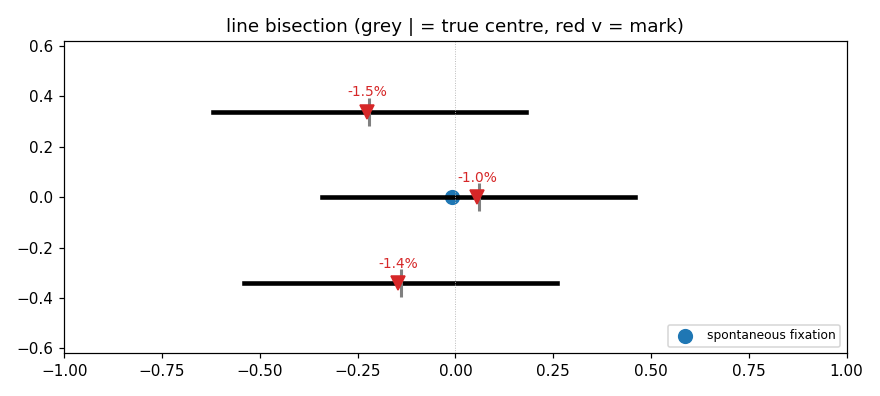

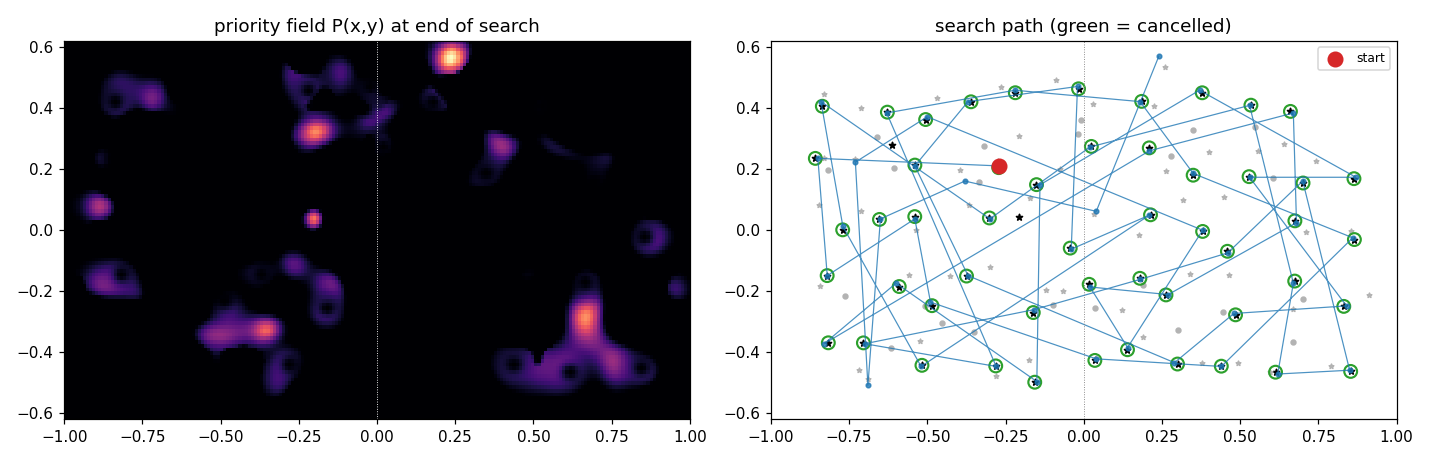

#### moderate

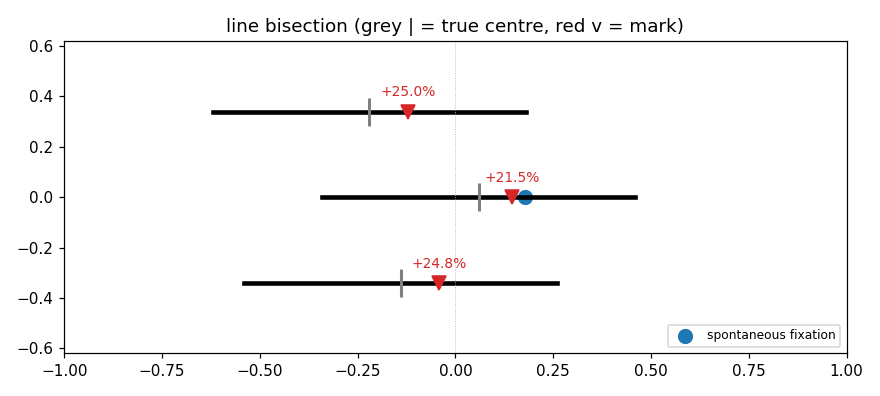

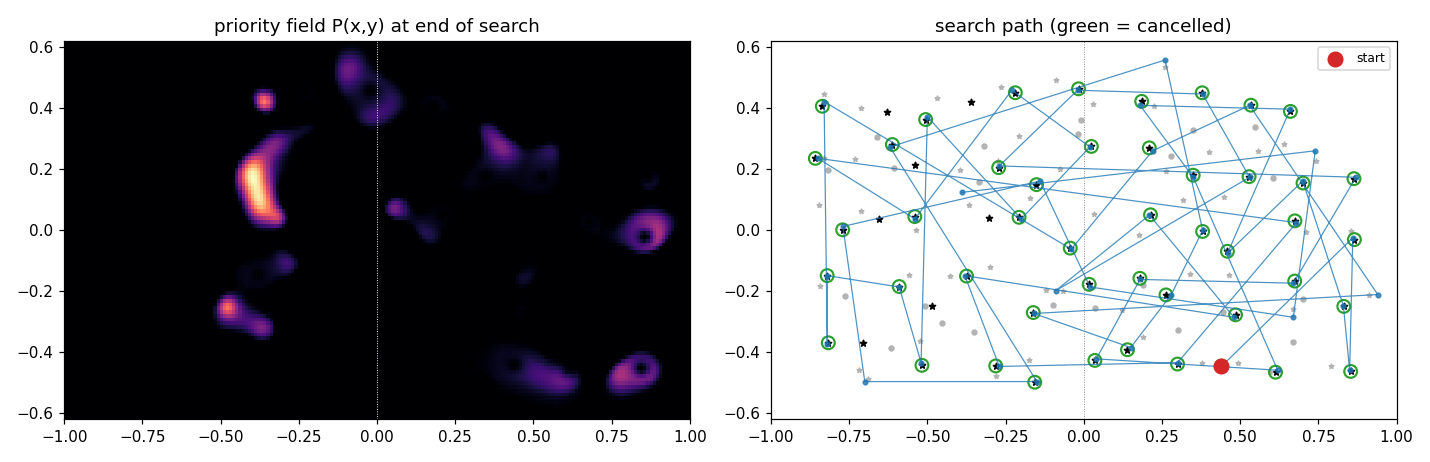

#### premotor

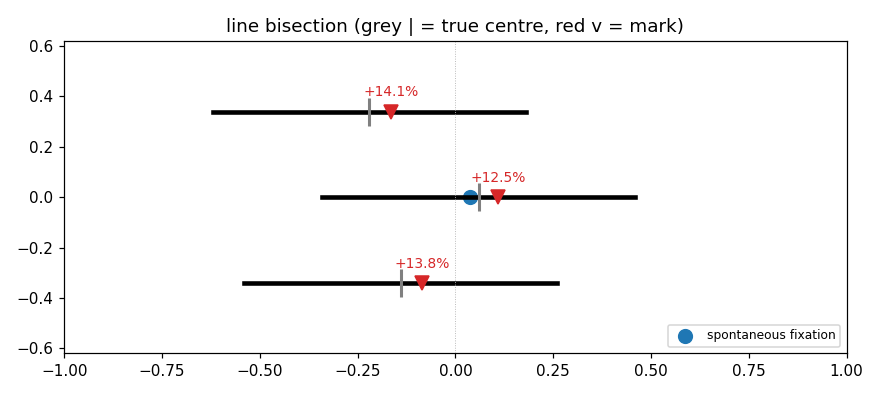

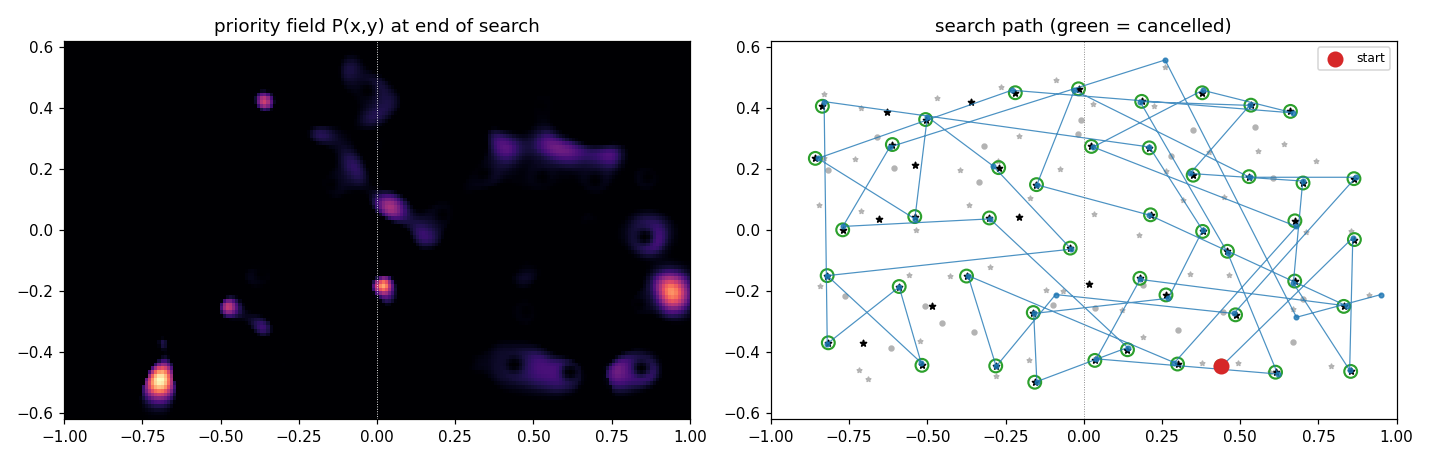

#### severe

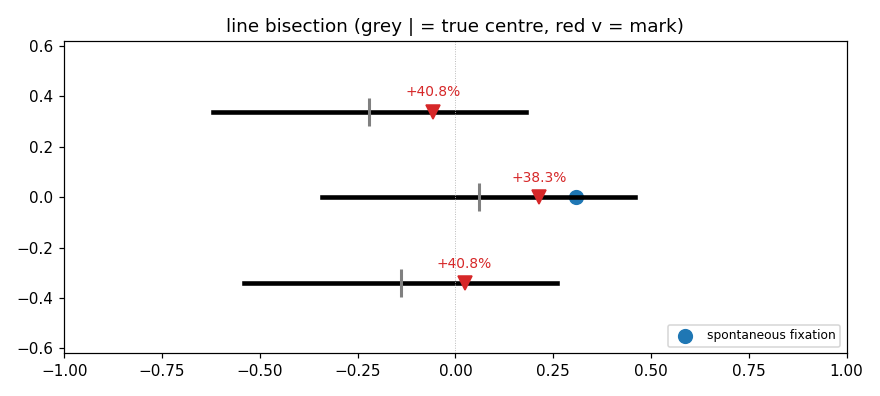

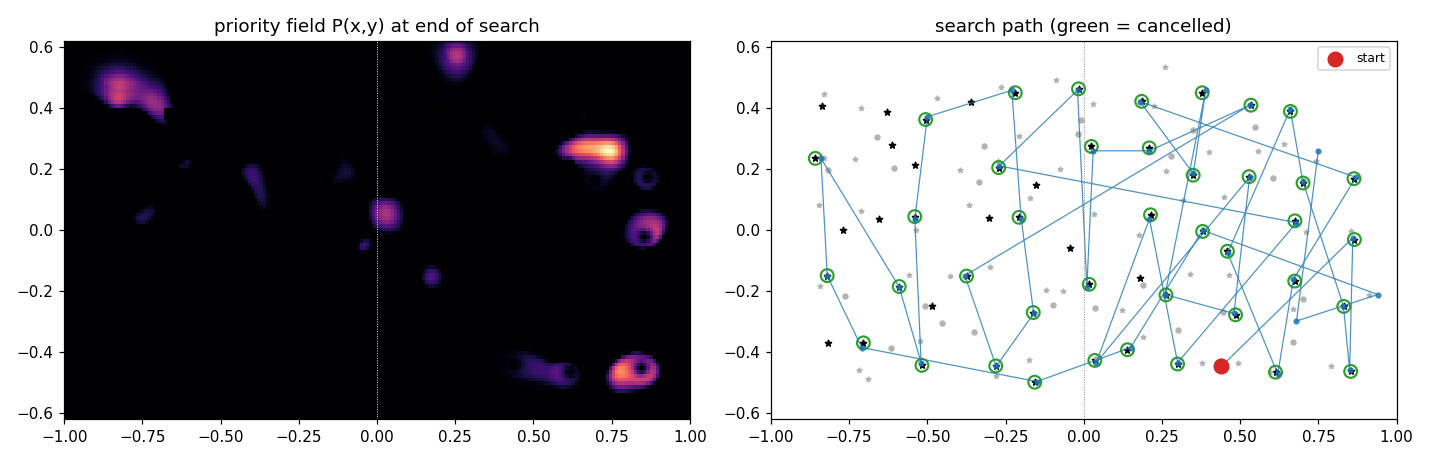

In [14]:
from IPython.display import Image, display, Markdown

if HAS_MPL:
    for name in sorted(FIGSET):
        display(Markdown(f"#### {name}"))
        bpath, spath = f"out/{name}/bisection.png", f"out/{name}/star.png"
        if os.path.exists(bpath):
            display(Image(filename=bpath))
        if os.path.exists(spath):
            display(Image(filename=spath))
else:
    print("matplotlib not available; figures were skipped.")


## 4. 対話的なカスタム実行

任意のパラメータ・任意の刺激で1回実行する例。`healthy()` を基点に、
知りたいパラメータだけ `copy_with(...)` で上書きする。

=== bisection ===
{
  "mean_pct_dev": 29.539394696192147,
  "mean_pct_dev_sd": 0.0,
  "bit_line_bisection_score": 1.0,
  "per_line": [
    {
      "y": 0.34,
      "pct_dev": 30.581861039559836,
      "pct_dev_sd": 3.552713678800501e-15
    },
    {
      "y": 0.0,
      "pct_dev": 27.388295963656002,
      "pct_dev_sd": 0.0
    },
    {
      "y": -0.34,
      "pct_dev": 30.648027085360606,
      "pct_dev_sd": 0.0
    }
  ],
  "fixation": [
    0.22438356164383563,
    0.0
  ],
  "neglect_sign": "right"
}

=== star cancellation ===
{
  "n_cancelled": 42.333333333333336,
  "n_cancelled_sd": 2.1343747458109497,
  "n_left_cancelled": 16.166666666666668,
  "n_left_cancelled_sd": 2.034425935955617,
  "n_right_cancelled": 26.166666666666668,
  "n_right_cancelled_sd": 0.3726779962499649,
  "left_omissions": 10.833333333333334,
  "left_omissions_sd": 2.034425935955617,
  "right_omissions": 0.8333333333333334,
  "right_omissions_sd": 0.37267799624996495,
  "centre_of_cancellation": 0.135378713

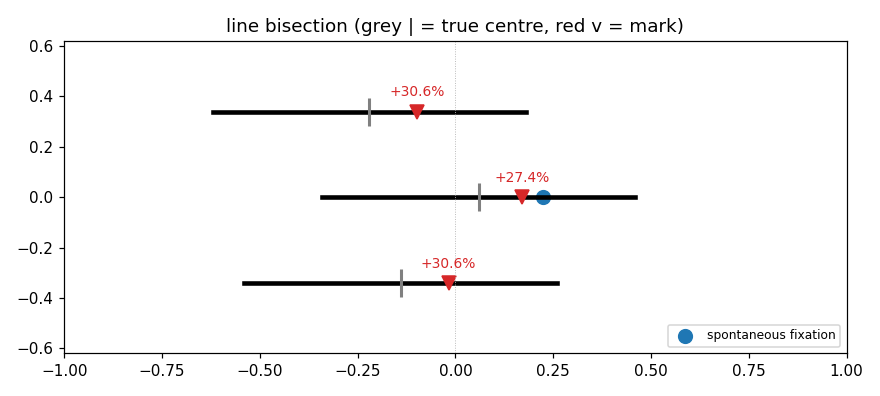

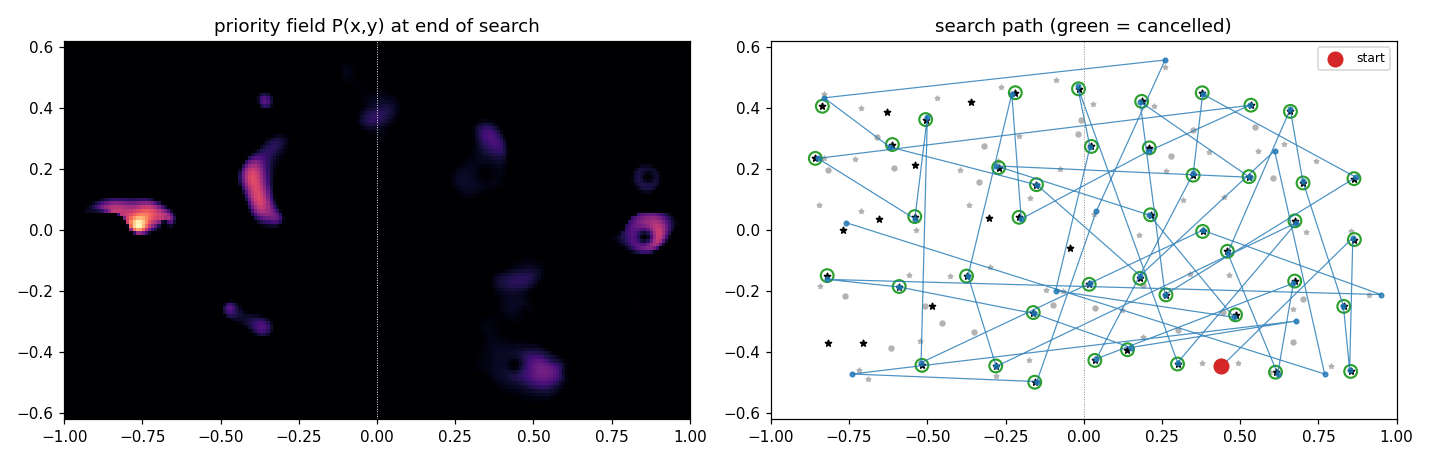

In [15]:
# 例: 右半球の gain をまとめて 0.5 前後まで下げたカスタム損傷
custom = healthy().copy_with(
    rho_bu_R=0.50, rho_td_R=0.50, rho_tpj_R=0.45, rho_gate_R=0.60, lc=0.85,
)
custom._preset = "custom"

b_custom = runmod.run_bisection(custom, out="out/custom", fig=HAS_MPL, n_seeds=6)
s_custom = runmod.run_star(custom, out="out/custom", fig=HAS_MPL, n_seeds=6)

print("=== bisection ===")
print(json.dumps(b_custom, indent=2)[:1200])
print("\n=== star cancellation ===")
print(json.dumps(s_custom, indent=2)[:1200])

if HAS_MPL:
    display(Image(filename="out/custom/bisection.png"))
    display(Image(filename="out/custom/star.png"))


独自のパラメータ／刺激を JSON として保存・読み込みすることもできる
（`6_simulation00.md` §4）:

```python
custom.to_json("out/my_params.json")
p2 = Params.from_json("out/my_params.json")

save_stim(bit_star_cancellation(seed=3), "out/my_stim.json")
stim2 = load_stim("out/my_stim.json")
```


## 5. 較正（`calibrate.py`）の実行例

群平均データ（または合成データ）に、損傷パラメータ5つ
（`rho_bu_R, rho_td_R, rho_tpj_R, rho_gate_R, lc`）を当てはめる。
**所要時間の目安: 1〜5分**（環境・`seeds`・`random` により変動。実測では約2〜5分）。
ここでは動作確認用に軽量設定（`seeds=42, random=10`）で実行する。

In [ ]:
# 合成の目標値（実データがあればこの dict を実測の平均値に置き換える）
targets = {
    "bisection_pct_dev":   (22.0, 1.0),   # (値, 重み)
    "star_left_omissions": (10.0, 1.5),
    "star_right_omissions": (0.5, 0.5),
    "star_CoC":            (0.17, 1.5),
    "star_n_cancelled":    (43.0, 1.0),
}

t0 = time.time()
fit_result = calibmod.fit(targets, seeds=42, n_random=10, seed=0)
print(f"calibration done in {time.time()-t0:.1f}s")

fit_result["targets"] = {k: v[0] for k, v in targets.items()}
with open("out/fit.json", "w", encoding="utf-8") as f:
    json.dump(fit_result, f, indent=2)

print(json.dumps(fit_result, indent=2))


`fit_result["theta"]` が最適化された損傷パラメータ、`fit_result["simulated"]` が
そのパラメータでのシミュレーション結果（`targets` と比較する）。実データで
較正する場合は `targets` の値を実測平均に、`seeds`/`n_random` を増やして精度を上げる
（`7_simulation_manual.md` §6 参照）。

## 6. 結果のダウンロード

`out/` フォルダ（スコアJSON・固視トレースCSV・図PNG・`demo_summary.csv`・`fit.json`）を
zip にまとめ、Colab 上で実行している場合はブラウザへダウンロードする。
ローカル Jupyter 等 Colab 以外で実行した場合は zip の作成のみ行う
（`out/` はランタイムのファイルシステムに残る）。

In [ ]:
import shutil

zip_base = "hemi_neglect_sim_out"
zip_path = shutil.make_archive(zip_base, "zip", "out")
print("archived:", zip_path, f"({os.path.getsize(zip_path)/1024:.1f} KB)")

if IN_COLAB:
    from google.colab import files
    files.download(zip_path)
else:
    print("not in Colab: skip browser download; the zip/out folder remain on disk.")


## 1. 目的とスコープ

### 1.1 目的

空間的注意の中核ループ（`IPS` 頭頂間溝（＋上頭頂小葉）・`FEF` 前頭眼野・`TPJ`側頭頭頂結合部・`VFC` 腹側前頭皮質（下前頭回）・`caudate` 尾状核・`putamen` 被殻・`GPi-SNr` 淡蒼球内節＋黒質網様部・`contra-FPN` 左半球の前頭頭頂注意ネットワーク・`LC` 青斑核 に相当する機構）を 2 次元の力学系モデルで表現し、右半球の損傷パラメータを変えることで、BIT の 2 課題（線分二等分・星印抹消）の成績を定量的に模倣する。

### 1.2 対象課題

- **線分二等分**（line bisection）: 3本の水平線分の中点を判断する課題。
- **星印抹消**（star cancellation）: 小さい星（標的）を大きい星・文字・単語（妨害子）の中からすべて探して消す課題。

### 1.3 スコープ外（HCD/FRGには存在するが本モデルには実装していない要素）

| 要素 | 本モデルでの扱い |
| --- | --- |
| 小脳ループ（`cerebellar-cortex`, `dentate`, remapping） | 未実装 |
| 後頭葉の視覚階層（`V1`,`V2-V4`,`V3A-MT` の特徴処理） | 単一の顕著性場に単純化（特徴弁別なし） |
| `ACC 前帯状皮質`/`limbic-value`（動機的価値・葛藤） | 未実装 |
| `SNc`（ドーパミン・報酬予測誤差）、直接路/間接路/hyperdirect の分離 | 単一の方向依存ゲイン `rho_gate` に単純化 |
| 物体中心（allocentric）座標、心像生成（表象無視） | 未実装（網膜/自我中心座標 `x` のみ） |


## 2. 座標系

| 記号 | 意味 | 範囲 |
| --- | --- | --- |
| `x` | **page (紙面)座標** の水平座標。刺激シート上に固定された座標で、目の動きとは無関係。**x<0 = 左 = 対側**（右半球損傷なら neglect 側）$x < 0 =$ 左 対側（右半球損傷なら neglect 側） | [-1, +1] |
| `y` | **page 座標の垂直成分**  | [-0.62, +0.62] |
| 格子 | `nx=201, ny=101` の一様格子（`Params.nx/ny`） | — |
| `f=(fx,fy)` | 現在の固視位置（紙面座標） | — |
| 網膜座標 | `retinal = page − f` | — |


## 3. モデルアーキテクチャ（データフロー）

```
刺激アイテム（位置・サイズ・target/distractor・match）
   │  salience(items, fx, fy)
   ▼
S_bu(x,y)  ボトムアップ顕著性        [U.V1],[U.V2-V4],[U.V3A-MT] 相当（特徴分化なし）
S_td(x,y)  標的テンプレート一致重み   [U.DLPFC] 相当
   │
   ▼  priority(S_bu, S_td, IOR, fx)
P_L(x,y), P_R(x,y)  半球別 priority 場   [U.IPS] 相当（R.priority-map-core）
   │  × gate_field(x,y)
   ▼
drive(x,y)
   │  accumulator: a += dt(k·drive·g_LC − leak·a) + noise
   ▼
a(x,y)   [U.FEF] 相当（R.cortical-target-selection）
   │  argmax, 閾値到達でサッカード
   ▼
新固視 → IOR付与 → 標的なら Go 判定して抹消（doneマスク） → 停止判定
```

線分二等分は上記ループを回さず、`priority` の定常形（opponent 版）から
1回の計算で判断点を求める<!--（§6.8）-->。


## 4. 入力仕様

### 4.1 パラメータ（`Params` データクラス、`sim/params.py`）

損傷は「領域の削除」ではなく、**右半球の gain を 1.0 未満に下げること**で表現する。

| パラメータ | 既定値（健常） | 意味 |
| --- | --- | --- |
| `rho_bu_L`, `rho_bu_R` | 1.00 | ボトムアップ顕著性の半球別ゲイン |
| `rho_td_L`, `rho_td_R` | 1.00 | トップダウン重みの半球別ゲイン |
| `rho_tpj_L`, `rho_tpj_R` | 1.00 | 解放（disengage）ゲイン |
| `rho_gate_L`, `rho_gate_R` | 1.00 | 方向特異的 BG Go ゲイン |
| `w_callosal` | 0.55 | 半球間競合（脳梁 opponent 項）の強さ |
| `hemi_out_exp` | 1.7 | 正規化後ゲインの急峻さ |
| `lc` | 1.00 | 覚醒/vigilance レベル [0,1] |
| `arousal_base`, `arousal_slope` | 0.55, 0.55 | `gain_arousal() = base + slope·lc` |
| `lambda_ecc` | 1.4 | 網膜離心度の減衰スケール |
| `beta_hemi` | 0.16 | 半球重み `wL/wR` シグモイドの幅 |
| `ipsi_floor` | 0.08 | 同側半球による残余表現の下限 |
| `norm_sigma`, `norm_kmax` | 0.05, 0.35 | 分割正規化の半飽和・最大値プール寄与率 |
| `n_field_iter` | 4 | 半球結合場の Gauss-Seidel 反復数 |
| `fmatch_floor`, `fmatch_eps` | 0.18, 0.15 | 特徴一致ゲート（distractor 弁別）のパラメータ |
| `w_ior`, `a_ior`, `sigma_ior`, `tau_ior` | 2.2, 2.4, 0.070, 9.0 | 一過性探索抑制（IOR）の強度・振幅・幅・時定数 |
| `k_acc`, `leak_acc`, `theta_sacc`, `dt_acc`, `max_inner`, `noise_acc` | 1.6, 0.35, 1.0, 0.02, 400, 0.012 | FEF accumulator のドライブ・漏れ・閾値・時間刻み・ノイズ |
| `r_mark`, `theta_mark` | 0.06, 0.30 | 抹消判定の許容半径・Go 閾値 |
| `max_saccades`, `min_saccades`, `patience`, `give_up_frac` | 140, 10, 3, 0.46 | 探索の最大/最小サッカード数、終了までの停滞許容数、終了閾値（健側初期ピーク比） |
| `fix_bias_gain`, `beta_hemi_line`, `k_periph`, `delta_motor`, `c_crossover`, `L_ref` | 0.42, 0.45, 1.0, 0.14, 0.0, 0.80 | 線分二等分専用パラメータ（§6.8） |
| `seed` | 0 | 乱数シード | — |

全項目は `Params.to_json(path)` / `Params.from_json(path)` で JSON として入出力できる <!--（§4.3）-->。

### 4.2 刺激仕様

**線分二等分**（`{"lines": [...], "display_items": [...]}`）
```json
{"lines": [{"x_left": -0.62, "x_right": 0.18, "y": 0.34}, ...]}
```
各線分は `x_left, x_right, y`（紙面座標）で定義。標準刺激は `stimuli.bit_line_bisection()` が
BIT 様の 3 本構成（中心座標を上段でやや左、中段で中央、下段でやや左に配置）を生成する。

**星印抹消**（`{"items": [...], "targets": [...], "target_index": [...]}`）
```json
{"x": 0.12, "y": -0.30, "sigma": 0.028, "amp": 0.85, "match": 1.0, "kind": "small_star", "target": true}
```
`items` は全アイテム（標的＋妨害子）、`targets` はそのうち標的（小さい星）のサブセット。
`match∈[0,1]` は課題テンプレートとの一致度（標的= 1.0、妨害子はそれより低い値）。
標準刺激は `stimuli.bit_star_cancellation(seed)` が小さい星 54 個・大きい星 52 個・文字 13 個・
単語 10 個を統計的に均等な配置で生成する（BIT の著作権レイアウトそのものではない）。

### 4.3 ファイル形式（入力）
- パラメータ: `params.json`（`Params` の全フィールドをそのまま JSON化）
- 刺激: `stim.json`（§4.2 の形式）



## 5. 計算モデル仕様

以下、`sim/model.py` の実装に対応する式を示す。`X, Y` は格子座標、`p.*` は `Params` の値。

### 5.1 顕著性場

$$
\text{eec}_i = \frac{1}{1+\frac{r_i}{\lambda_{\text{ecc}}^{2}}}
$$

$r_i=\left\|(X,Y)-\text{item}_i\right\|$ (固視基準)

$$
S_{bu}(X,Y) = \sum_i \text{amp}_i \cdot \text{ecc}_i\cdot
\exp\left(-\left\|(X,Y)-\text{pos}_i\right\|^{2}/2\sigma_{i}^{2}\right)
$$

$$
S_{td} = \sum_i \text{match}_i \cdot \text{amp}_i\cdot \text{ecc}_{i}\cdot\exp()
$$
<!--
```
ecc_i        = 1 / (1 + (r_i/λ_ecc)^2)                     r_i = ‖(X,Y) − item_i‖（固視基準）
S_bu(X,Y)    = Σ_i  amp_i · ecc_i · exp(−‖(X,Y)−pos_i‖^2 / 2σ_i^2)
S_td(X,Y)    = Σ_i  match_i · amp_i · ecc_i · exp(...)
``` -->

### 5.2 半球重み（網膜部位）
```
wR(X) = ipsi_floor + (1−ipsi_floor)·σ(−(X−fx)/β_hemi)     右半球は左網膜野を優位に代表
wL(X) = ipsi_floor + (1−ipsi_floor)·σ( (X−fx)/β_hemi)
```

### 5.3 特徴一致ゲート（distractor 弁別）
```
Mnorm      = clip(S_td / (S_bu+ε), 0, 1)
floor_h    = 1 − min(rho_td_h,1)·(1−fmatch_floor)           top-down が弱い半球は floor が高い
fmod_h     = floor_h + (1−floor_h)·Mnorm
```

### 5.4 半球別 priority 場（Gauss-Seidel 反復、n_field_iter 回）
```
R_L = (rho_bu_L·wL·S_bu + rho_td_L·wL·S_td)·fmod_L − w_ior·IOR − w_callosal·mirror_x(P_R)
R_R = (rho_bu_R·wR·S_bu + rho_td_R·wR·S_td)·fmod_R − w_ior·IOR − w_callosal·mirror_x(P_L)
R_L, R_R ← ReLU(R_L), ReLU(R_R)
denom = norm_sigma^2 + mean(R_L+R_R) + norm_kmax·max(R_L+R_R)     ← 半球共有の正規化プール
P_L = g_LC · R_L / denom ,  P_R = g_LC · R_R / denom              g_LC = arousal_base+arousal_slope·lc
P_L ×= (½(rho_bu_L+rho_td_L))^hemi_out_exp
P_R ×= (½(rho_bu_R+rho_td_R))^hemi_out_exp
P = P_L + P_R
```
`mirror_x` は `x=0` について左右反転する写像（脳梁 opponent 項、`[U.contra-FPN]` 相当）。
正規化プールが半球で**共有**である点が、弱い半球が競合に絶対的に負ける仕組みの核心
（`sim/DESIGN_LOG.md` §3.2・§4「仮定C」参照）。

### 5.5 方向特異的 BG ゲート
```
ego(X) = σ(−X/0.10)              紙面上で左であるほど1に近づく（自我中心）
ret(X) = σ(−(X−fx)/0.10)         現固視より左であるほど1に近づく（網膜）
left_frac = 0.75·ego + 0.25·ret
gate(X) = rho_gate_L·(1−left_frac) + rho_gate_R·left_frac
```

### 5.6 FEF accumulator とサッカード選択
```
drive = ReLU(P) · gate
a ← 0.04·a                                        （試行間の残存を小さく保つ）
繰り返し（最大 max_inner 回）:
    a += dt_acc·(k_acc·drive·g_LC − leak_acc·a) + noise_acc·√dt_acc·N(0,1)
    a ← max(a,0)
    a.max() ≥ theta_sacc なら打ち切り
新固視 = argmax(a) の座標
```

### 5.7 IOR と done マスク
```
IOR ← IOR·exp(−1/tau_ior)                          一過性減衰
IOR += a_ior·Gauss(退出地点) + a_ior·Gauss(到着地点)
標的を抹消したとき: done ×= 1 − Gauss(その位置; 幅 1.4σ_ior)     （恒久的、減衰しない）
P_effective = ReLU(P) · done
```

### 5.8 抹消判定
```
移動方向が左向き（x*<fx）なら rho_gate_dir = rho_gate_R、そうでなければ rho_gate_L
go = rho_gate_dir · (a.max()/theta_sacc) · match_target
go ≥ theta_mark かつ未抹消 → 抹消（marked に追加）
既に抹消済みの標的への再着地 → 「保続的再固視」として記録（revisits）
```

### 5.9 停止規則
```
step+1 ≥ min_saccades のとき:
    rem_max = max(ReLU(P)·done)                     「表象している」残余 priority
    stale   = 現ステップ − 最後に何か見つけたステップ
    rem_max < give_up_frac · p0_max  かつ  stale ≥ patience  → 終了
    stale ≥ patience+8                                → 強制終了
```
`p0_max` は探索開始時点での**健側**（紙面右半分）の priority 最大値に固定した参照値
（重症度が変わっても閾値の基準がぶれないようにするため。DESIGN_LOG §3.2 バグ3参照）。

### 5.10 線分二等分（定常形）
```
sRH = rho_bu_R + rho_td_R,  sLH = rho_bu_L + rho_td_L
sRH_eff = sRH^2 / (sRH + w_callosal·sLH)            半球間の除算型相互抑制
sLH_eff = sLH^2 / (sLH + w_callosal·sRH)
fx_hab  = fix_bias_gain · (sLH_eff − sRH_eff) / (sLH_eff + sRH_eff)   自発固視位置

rep(x) = [sLH_eff·σ((x−fx_hab)/β) + sRH_eff·σ(−(x−fx_hab)/β)] × comp(x)
comp(x) = 1                                           （x ≥ fx_hab）
comp(x) = exp(−k_periph·(1−sRH_eff/sLH_eff)·(fx_hab−x))  （x < fx_hab、左方圧縮）

b_perc = rep(x) の（線分区間上での）累積分布の中央値
motor  = delta_motor·(1−rho_gate_R)·half_length
b_mark = b_perc + motor − c_crossover·(L_ref − line_length)
pct_dev = 100·(b_mark − 真の中点) / half_length         正 = 右方偏倚
```

---

## 6. 出力仕様

### 6.1 共通の内部変数
`P(x,y)`（統合 priority 場）、`fixations`（固視系列）、`a(x,y)`（accumulator 状態、実行時のみ）。

### 6.2 線分二等分（`bisection_scores.json`）
| フィールド | 内容 |
| --- | --- |
| `mean_pct_dev` | 3本平均の符号付き偏倚 %。**正=右方（病側）**、負=左方 |
| `bit_line_bisection_score` | BIT帯域点の近似（0〜9、高いほど正常） |
| `lines[]` | 各線分の `true_center, b_mark, pct_dev, bit_points` |
| `fixation` | 自発固視位置 `(fx_hab, 0)` |
| `neglect_sign` | `"right"`/`"left"`/`"none"`（平均偏倚の閾値 ±2% で判定） |

### 6.3 星印抹消（`star_scores.json`）
| フィールド | 内容 |
| --- | --- |
| `n_cancelled` | 抹消総数（/54） |
| `left_omissions`, `right_omissions` | 左右半分（紙面正中基準）の見落とし数（各/27） |
| `centre_of_cancellation` | CoC（−1〜+1、正=右に偏る。Rorden & Karnath 2010 近似） |
| `revisits` | 保続的再固視の回数 |
| `path_length`, `n_saccades`, `total_time` | 探索経路長、サッカード数、所要時間（任意単位） |
| `start_quadrant` | 最初のサッカードの向き（"left"/"right"/"centre"） |
| `bit_star_score` | `n_cancelled` と同義（BIT表記との対応） |
| `neglect_flag` | 左右差または CoC から無視ありと判定したブール値 |

`star_trace.csv` は `step, x, y, t, marked_id` の固視系列（`marked_id` は抹消したアイテムの
インデックス、−1=未抹消、−2=保続的再固視）。

### 6.4 ファイル形式（出力）
JSON（スコア）、CSV（固視トレース）、PNG（`--fig` 指定時、priority 場と探索経路の可視化、
または二等分の判断点の可視化）。`demo_summary.csv` は `--demo` 実行時の全プリセット横断表。




---

## 7. プリセット（`params.PRESETS`）

| プリセット | `rho_bu_R` | `rho_td_R` | `rho_tpj_R` | `rho_gate_R` | `lc` | 想定する無視のタイプ |
| --- | --- | --- | --- | --- | --- | --- |
| `healthy` | 1.03 | 1.02 | 1.00 | 1.00 | 1.00 | 健常（pseudoneglect） |
| `mild` | 0.82 | 0.82 | 0.68 | 0.88 | 0.95 | 軽度・混合型 |
| `moderate` | 0.60 | 0.58 | 0.46 | 0.68 | 0.87 | 中等度・混合型 |
| `severe` | 0.36 | 0.32 | 0.26 | 0.44 | 0.74 | 重度・混合型 |
| `perceptual` | 0.40 | 0.42 | 0.55 | 0.92 | 0.90 | 入力型（知覚性）無視 |
| `premotor` | 0.90 | 0.90 | 0.80 | 0.33 | 0.95 | 出力型（方向性運動低下） |
| `disengage` | 0.80 | 0.80 | 0.22 | 0.85 | 0.90 | disengage 優位型 |

`healthy` の左半球パラメータは常に 1.00（右半球のみわずかに強く、pseudoneglect を再現）。

---

## 8. 較正（`calibrate.py`）仕様

自由パラメータ `{rho_bu_R, rho_td_R, rho_tpj_R, rho_gate_R, lc}` を、群平均データ
（`metric,value,weight` 形式の CSV、metric は `bisection_pct_dev, star_left_omissions,
star_right_omissions, star_CoC, star_n_cancelled` のいずれか）に対し、ランダム探索
（既定30点）＋ Nelder-Mead 局所探索（scipy があれば）／座標降下（無ければ）で当てはめる。
損失関数は正規化二乗誤差の重み付き和。詳細は `7_simulation_manual.md` §7。

---

## 9. 既知の限界（§1.3 の再掲・詳細）

- パラメータは**未較正のデフォルト値**（手調整）。§8 の `calibrate.py` で実データに fit する前提。
- 物体中心（allocentric）無視・neglect dyslexia・表象無視・絶対 RT は範囲外。
- `contra-FPN` は左半球ネットワーク全体を単一の opponent 項に集約した近似。
- 星印抹消の刺激レイアウトは統計的に同等な生成品（BIT 著作権レイアウトではない）。
- 空間的な側方抑制の再帰カーネル（bump attractor の recurrent 項）は実装していない


<!-- ---
## 関連ドキュメント（リポジトリ内）

- `6_simulation00.md` — 仕様書（数式・入出力形式・プリセット定義）
- `7_simulation_manual.md` — 操作説明書（このノートブックのローカル版に相当）
- `sim/README.md` — 英語版の要約仕様
- `sim/DESIGN_LOG.md` — 設計判断の経緯・デバッグ履歴・無視生起メカニズムの仮定一覧
- `sim/References.csv` — 実装に直接関係する文献（44件） -->
